# Анализ и прогнозирование временных рядов методами искусственного интеллекта

## **Практическая работа 5. Поиск типичных подпоследовательностей временного ряда.**

In [1]:
%load_ext autoreload
%autoreload 2

Импорт библиотек и модулей

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from modules.snippets import *
from scipy import signal
from stumpy import snippets
import pandas as pd
from pathlib import Path
from IPython.display import display

assert Path('datasets').is_dir(), 'Откройте ноутбук из каталога практики 5.'
np.random.seed(42)

/Users/mikhail/Developer/2026-autumn/AFTSAIM-2026/.venv/lib/python3.12/site-packages/stumpy/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


### Задача 1. Поиск сниппетов одномерного временного ряда

В первой задаче необходимо выполнить поиск сниппетов одномерного временного ряда. Расмотрите приведенный ниже пример использования алгоритма SnipperFinder и визуализации полученных результатов для искуственного врменного ряда.

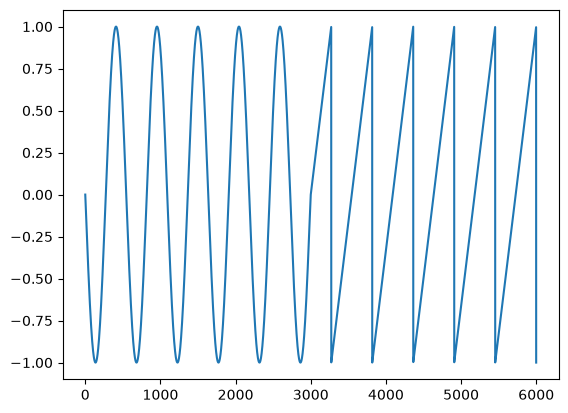

In [3]:
#Создание искусственного временного ряда
t = np.linspace(np.pi, 6 * 2 * np.pi, 3000)
ts = np.concatenate([np.sin(t), signal.sawtooth(t)])
plt.plot(ts)

In [4]:
#Поиск сниппетов
snp = snippets(ts, m=600, k=2, percentage=0.5)

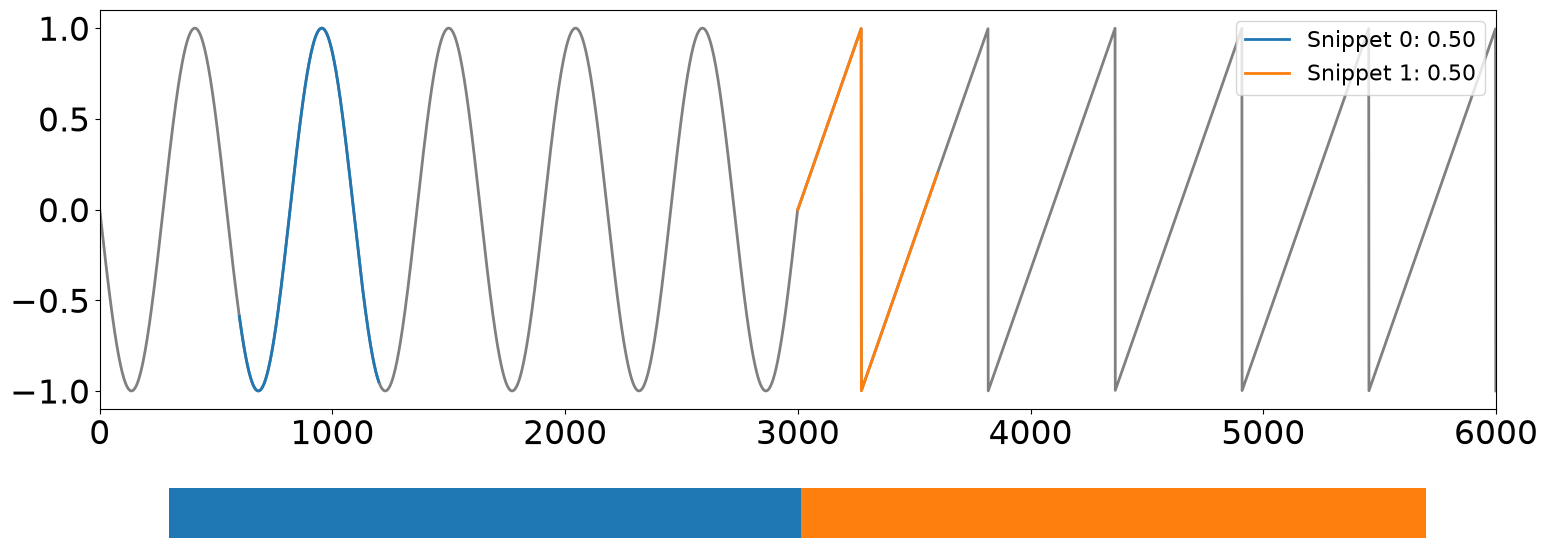

<Axes: >

In [5]:
#Визуализация результатов
plot_snippets(ts, snp)

Далее вам предстоит самостоятельно выполнить поиск top-$k$ типичных подпоследовательностей временного ряда (сниппетов) с помощью алгоритма SnippetFinder на наборе данных PAMAP. Описание набора данных находится в [README-файле](datasets/PAMAP/readme.md).

Выполните считывание временного ряда **показаний гироскопа на оси «Y» (угол тангажа) на временном интервале от 1790 сек. до 1930 сек.** (используя колонку с временными метками) из файла *PAMAP.txt*, который располагается в директории *./datasets/PAMAP*. Затем выполните поиск сниппетов с помощью функции `snippets()` из библиотеки stumpy. Затем визуализируйте полученные результаты, используя функцию `plot_snippets()` из модуля snippets.py.

In [6]:
# INSERT YOUR CODE
data_path = "datasets/PAMAP/PAMAP.txt"
pamap = np.loadtxt(data_path)

# Файл хранит признаки по строкам, отсчёты — по столбцам.
timestamp_col = pamap[0]
time_filter = (timestamp_col >= 1790) & (timestamp_col <= 1930)
timestamps = timestamp_col[time_filter]
gyroscope_axes = pamap[10:13, time_filter]
activity_ids = pamap[1, time_filter].astype(int)
gyroscope_data = gyroscope_axes[1]
assert np.isfinite(gyroscope_axes).all()
assert set(np.unique(activity_ids)) == {12, 13}
print(f'Отсчётов: {len(timestamps)}; интервал: {timestamps[0]:.2f}–{timestamps[-1]:.2f} с')

m, k, percentage = 600, 2, 0.5
snp = snippets(gyroscope_data, m=m, k=k, percentage=percentage)

Отсчётов: 13430; интервал: 1795.71–1930.00 с


Выполните визулизацию временного ряда и найденных сниппетов с помощью функции `plot_snippets()` из модуля snippets.py.

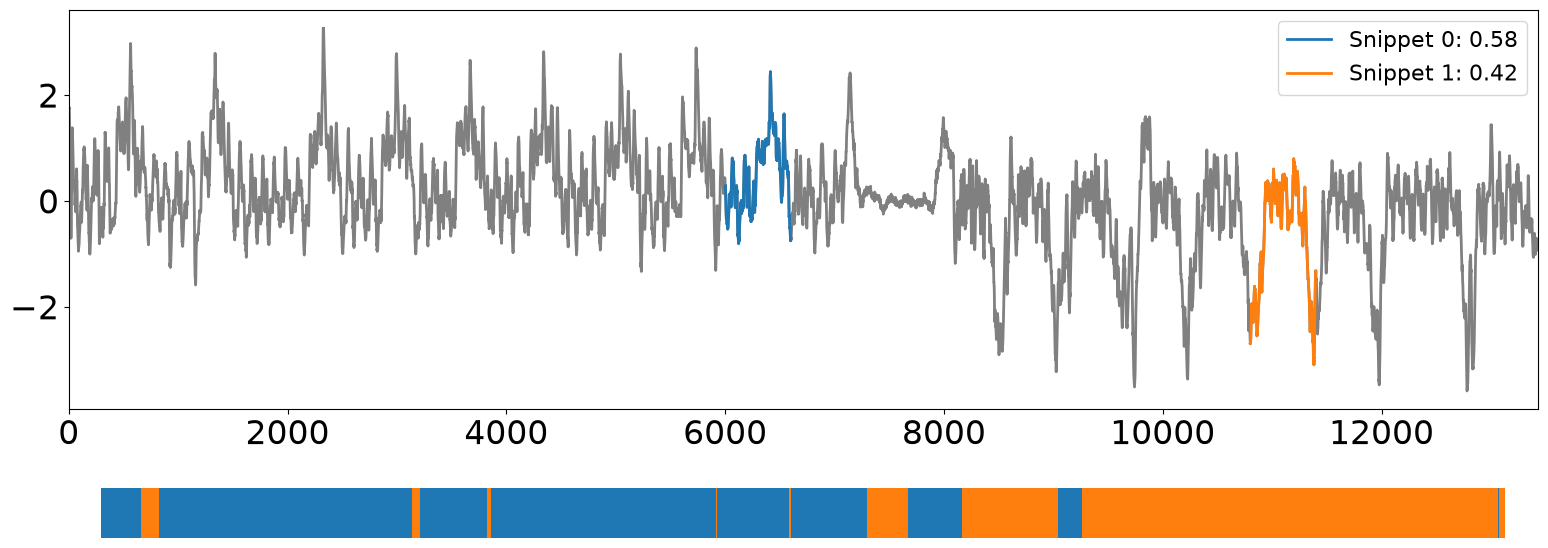

<Axes: >

In [7]:
# INSERT YOUR CODE
plot_snippets(gyroscope_data, snp)

Оцените точность разметки, полученной при помощи сниппетов, используя исходные данные об активностях в ряде.

In [8]:
# INSERT YOUR CODE
labels_y = regime_labels(snp, len(gyroscope_data))
centers = np.arange(len(labels_y)) + m // 2
true_labels = (activity_ids[centers] == 13).astype(int)

# Перестановка нужна только для метрики: 0 — подъём, 1 — спуск.
evaluated_y = align_binary_labels(labels_y, true_labels)
accuracy_y = np.mean(evaluated_y == true_labels)
print(f'Accuracy Y: {accuracy_y:.4%}; оценено окон: {len(labels_y)}')
print(f'Не размечены края: {centers[0]} слева, {len(timestamps)-1-centers[-1]} справа')
display(pd.DataFrame({'Начало': snp[1], 'Доля покрытия': snp[3]}))

Accuracy Y: 90.1644%; оценено окон: 12831
Не размечены края: 300 слева, 299 справа


,Начало,Доля покрытия
0,6000,0.578443
1,10800,0.421557


❓ Проанализируйте и изложите содержательный смысл полученных результатов.

На фактически доступном интервале **1795.71–1930.00 с** найдено два сниппета Y длиной 600 отсчётов (6 секунд). Они начинаются в позициях **6000** и **10800** выбранного фрагмента и представляют **57.84%** и **42.16%** его окон.

В этом интервале есть подъём и спуск по лестнице (метки 12 и 13). Accuracy после сопоставления произвольных ID сниппетов с активностями составляет **90.1644%** на **12831** окнах. Сравниваются метки центров окон; 300 точек слева и 299 справа не получают искусственного класса.

Число 86.35% из Telegram воспроизводится его способом оценки: ID окна приписывается его началу, а оставшийся хвост заполняется нулём. Это другая оценка, поэтому напрямую сравнивать её с accuracy по центрам окон нельзя. Две характерные формы в основном разделяют две активности, но не дают безошибочной разметки перехода и всех локальных движений.

### Задача 2. Разметка многомерного временного ряда

Выполните разметку многомерного временно ряда, используя **показания гироскопа по всем трем осям** из набора данных PAMAP. Используйте тот же временной интервал, что и в задаче 1. Итоговую разметку получите в результате голосования большинством.

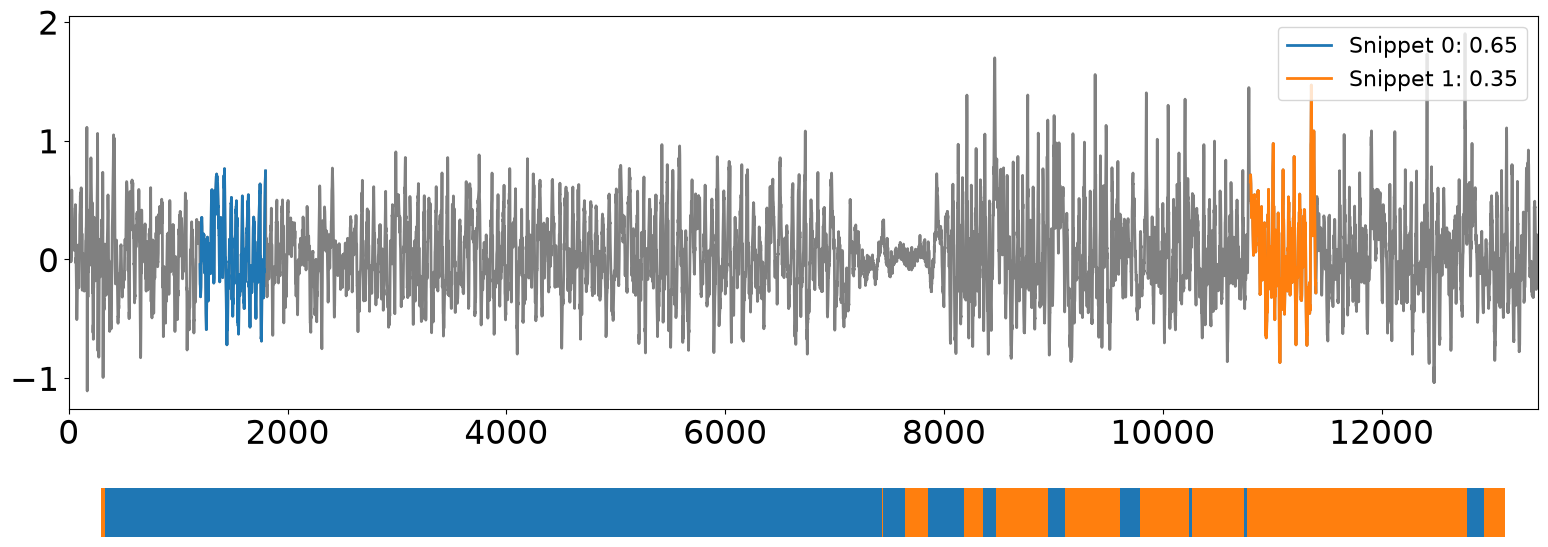

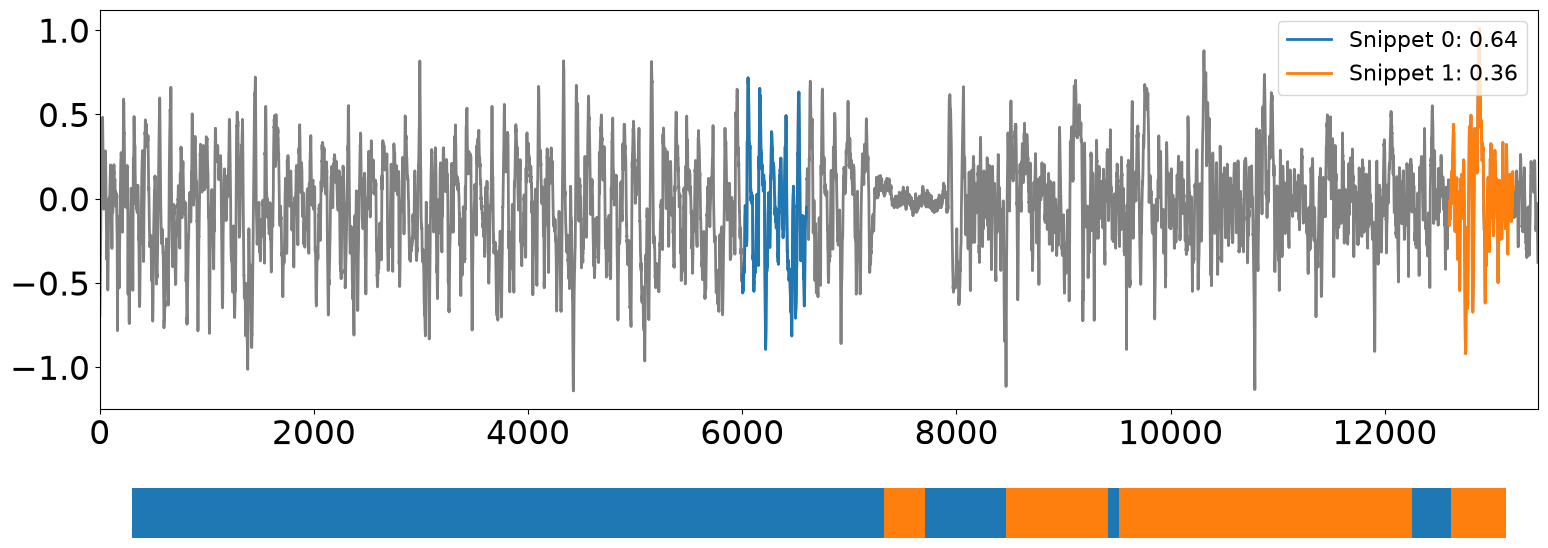

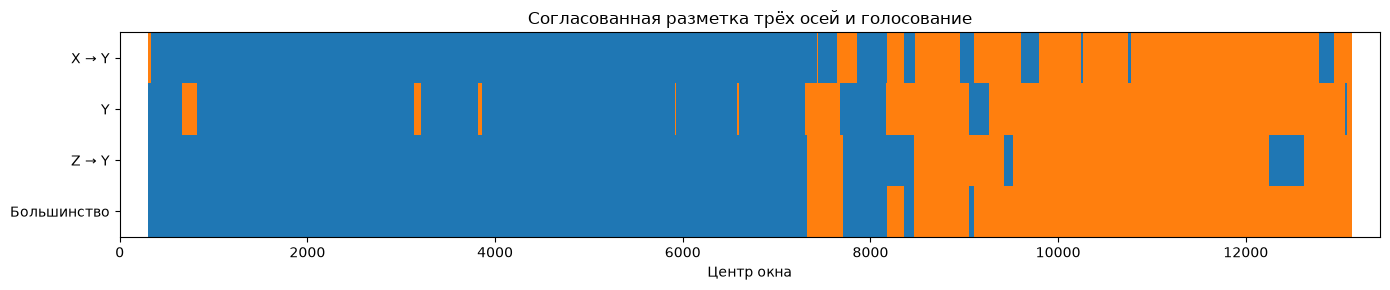

In [9]:
# INSERT YOUR CODE
axis_names = ['X', 'Y', 'Z']
axis_snippets = {'Y': snp}
axis_labels = {'Y': labels_y}
for axis, series in zip(axis_names, gyroscope_axes):
    if axis != 'Y':
        axis_snippets[axis] = snippets(series, m=m, k=k, percentage=percentage)
        axis_labels[axis] = regime_labels(axis_snippets[axis], len(series))
        plot_snippets(series, axis_snippets[axis])

# Голосуем после согласования ID осей с Y, без истинной разметки.
aligned_axes = np.array([align_binary_labels(axis_labels[axis], labels_y)
                         for axis in axis_names])
voted_labels = majority_vote(aligned_axes)
fig, ax = plt.subplots(figsize=(14, 3))
ax.imshow(np.vstack([aligned_axes, voted_labels]), aspect='auto',
          interpolation='nearest', cmap='tab10', vmin=0, vmax=9,
          extent=(centers[0]-.5, centers[-1]+.5, 3.5, -.5))
ax.set(yticks=range(4), yticklabels=['X → Y', 'Y', 'Z → Y', 'Большинство'],
       xlabel='Центр окна', title='Согласованная разметка трёх осей и голосование')
ax.set_xlim(0, len(timestamps))
plt.tight_layout()
plt.show()

Оцените точность разметки многомерного ряда, используя исходные данные об активностях.

In [10]:
# INSERT YOUR CODE
accuracy_axes = {axis: float(np.mean(align_binary_labels(axis_labels[axis], true_labels)
                                     == true_labels)) for axis in axis_names}
accuracy_vote = float(np.mean(align_binary_labels(voted_labels, true_labels) == true_labels))
accuracy_table = pd.DataFrame({'Accuracy': {**accuracy_axes, 'Голосование': accuracy_vote}})
display(accuracy_table)
print('Все оценки рассчитаны на одинаковых центрах окон:', len(true_labels))

,Accuracy
X,0.910529
Y,0.901644
Z,0.888395
Голосование,0.934378


Все оценки рассчитаны на одинаковых центрах окон: 12831


❓ Проанализируйте и изложите содержательный смысл полученных результатов. Сравните полученные разметки многомерного и одномерного рядов.

Accuracy на одних и тех же **12831** центрах окон:

| Метод | Accuracy |
|---|---:|
| X | 91.0529% |
| Y | 90.1644% |
| Z | 88.8395% |
| Большинство трёх осей | 93.4378% |

Перед голосованием номера кластеров X и Z согласованы с Y по взаимному совпадению, без истинных меток. Голосование улучшило результат относительно Y на **3.27 процентного пункта**: ошибки отдельных осей не полностью совпадают. Истинные метки используются только при итоговой оценке соответствия кластеров активностям. Это оценка разметки данного фрагмента, а не результат обучения и проверки на независимой выборке.

### Задача 3. Подбор оптимального значения _k_


Разработайте программу, которая выполняет выполняет вычисление меры $change$ для различных значений $k$ с помощью алгоритма SnippetFinder. Проведите эксперименты, используя временной ряд из задания 2 (взяв 1 ≤ _k_ ≤ 9).

$Change_k = \frac{ProfileArea_{k-1}}{ProfileArea_k} - 1$

In [11]:
# INSERT YOUR CODE
k_values = np.arange(1, 10)
search_results = {}
for axis, series in zip(axis_names, gyroscope_axes):
    print(f'Подбор k: ось {axis}')
    search_results[axis] = snippets(series, m=m, k=9, percentage=percentage)

# STUMPY возвращает накопленную площадь после каждого выбранного сниппета.
areas_by_axis = np.array([search_results[axis][4] for axis in axis_names])
profile_areas = areas_by_axis.mean(axis=0)
changes = profile_change(profile_areas)
best_k = int(k_values[1:][np.nanargmax(changes[1:])])
selection_table = pd.DataFrame({'k': k_values, 'ProfileArea': profile_areas, 'Change': changes})
display(selection_table)
print('Выбранное k по максимуму Change:', best_k)

Подбор k: ось X


Подбор k: ось Y


Подбор k: ось Z


,k,ProfileArea,Change
0,1,161070.924161,NaN
1,2,139223.412515,0.156924
2,3,126306.448594,0.102267
3,4,117643.701620,0.073635
4,5,109427.238178,0.075086
5,6,101712.854956,0.075845
6,7,94174.046524,0.080052
7,8,87268.441453,0.079131
8,9,80544.306686,0.083484


Выбранное k по максимуму Change: 2


Выполните визуализацию результатов экспериментов в следующем виде: отображение столбчатых диаграм со значениями $ProfileArea$ и меры $change$ в зависимости от $k$.

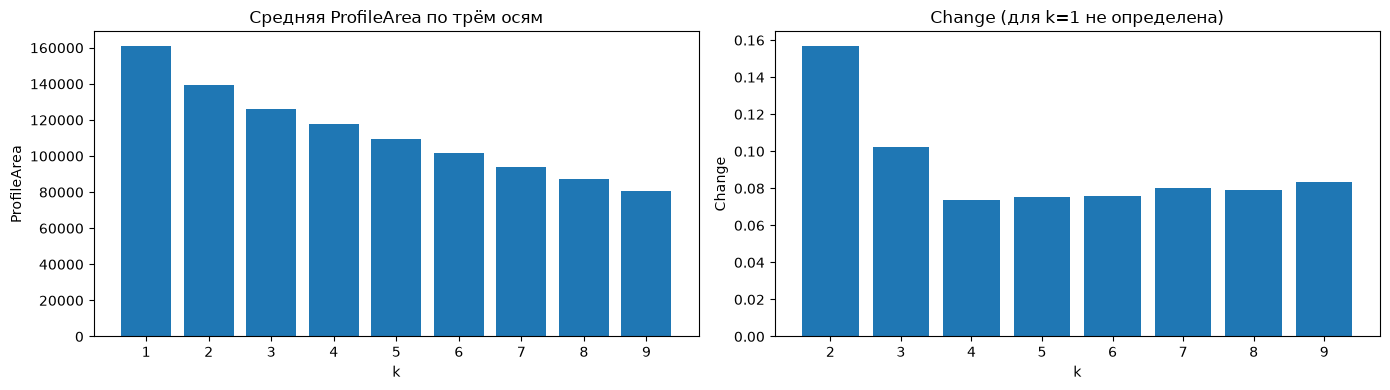

In [12]:
# INSERT YOUR CODE
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(k_values, profile_areas)
axes[0].set(title='Средняя ProfileArea по трём осям', xlabel='k', ylabel='ProfileArea', xticks=k_values)
axes[1].bar(k_values[1:], changes[1:])
axes[1].set(title='Change (для k=1 не определена)', xlabel='k', ylabel='Change', xticks=k_values[1:])
plt.tight_layout()
plt.show()

❓ Проанализируйте и изложите содержательный смысл полученных результатов. Какое значение $k$ является наилучшим для используемого временного ряда?

Наибольший пик меры Change приходится на **k=2**: **0.156924** при переходе от одного к двум сниппетам. Поэтому для этого трёхмерного фрагмента выбирается **два сниппета**. Выбор сделан по площадям профилей, без использования accuracy или истинного количества активностей.

Средняя ProfileArea уменьшается с **161070.92** при k=1 до **80544.31** при k=9. Однако само по себе уменьшение площади при добавлении сниппетов ожидаемо и не означает, что нужно выбирать k=9. После пика при k=2 относительное улучшение меньше. Для k=1 Change не определена, поскольку площадь для k=0 не задана.

In [13]:
import json
from pathlib import Path

assert len(timestamps) == 13430
assert len(labels_y) == len(timestamps) - m + 1
assert all(len(labels) == len(labels_y) for labels in axis_labels.values())
assert np.all((voted_labels == 0) | (voted_labels == 1))
for axis, result in axis_snippets.items():
    assert np.all((result[1] >= 0) & (result[1] + m <= len(timestamps)))
    np.testing.assert_allclose(result[3].sum(), 1, atol=1e-10)
    assert result[2].shape == (2, len(labels_y))
    np.testing.assert_array_equal(regime_labels(result, len(timestamps)), axis_labels[axis])
for result in search_results.values():
    assert result[2].shape == (9, len(labels_y))
    assert np.isfinite(result[4]).all()
    assert np.all(np.diff(result[4]) <= 1e-7)
    np.testing.assert_allclose(np.minimum.accumulate(result[2], axis=0).sum(axis=1), result[4], rtol=1e-8)
assert np.isnan(changes[0])
assert np.isfinite(changes[1:]).all()
summary = {
    'n': len(timestamps), 'evaluated': len(labels_y),
    'start': float(timestamps[0]), 'stop': float(timestamps[-1]),
    'accuracy_axes': accuracy_axes, 'accuracy_vote': accuracy_vote,
    'y_starts': snp[1].tolist(), 'y_fractions': snp[3].tolist(),
    'areas_by_axis': areas_by_axis.tolist(),
    'profile_areas': profile_areas.tolist(), 'changes': changes[1:].tolist(),
    'best_k': best_k,
}
Path('.cache/results.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2))
print('Проверки полного запуска пройдены')


Проверки полного запуска пройдены
